# NN_L10_hedge_costs

**Expected shortfall (95 %) of the hedging loss as a function of the transaction cost: Black-Scholes delta against a deep hedge trained for each cost level.**

Neural Networks and Deep Learning (NN), Lecture 10 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L10/NN_L10_hedge_costs/NN_L10_hedge_costs.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

delta hedge ES95, no cost (%) = 1.75   [hedge.bs_es_0]
delta hedge ES95, 50 bp (%) = 2.76   [hedge.bs_es_50]
deep hedge, one seed, 300 steps: [1.01, 1.08, 1.11, 1.31, 2.19]


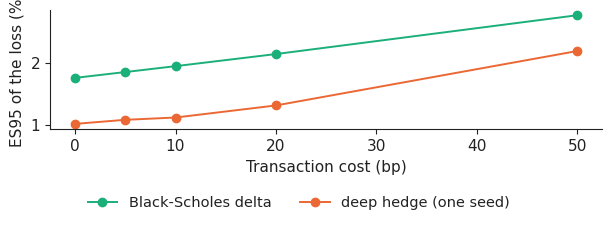

In [3]:
import torch, torch.nn as nn
m = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
w = m.pivot(index='date', columns='ticker', values='close').loc[:'2026-10-31']
px = w['SP500'].dropna(); vix = w['VIX'].reindex(px.index).ffill()
from scipy.stats import norm
S = px; VX = vix / 100; n = 21; lS = np.log(S.values); st = np.arange(len(S) - n)
paths = np.stack([np.exp(lS[i:i + n + 1] - lS[i]) for i in st]).astype(np.float32)
vols = np.stack([VX.values[i:i + n + 1] for i in st]).astype(np.float32); y0 = S.index[st].year
TAU = (n - np.arange(n + 1)) / 252.0
def bs_call(Sx, sg, tau):
    tau = np.maximum(tau, 1e-8); d1 = (np.log(Sx) + 0.5 * sg ** 2 * tau) / (sg * np.sqrt(tau))
    return Sx * norm.cdf(d1) - norm.cdf(d1 - sg * np.sqrt(tau)), norm.cdf(d1)
prem = bs_call(1.0, vols[:, 0], TAU[0])[0]; payoff = np.maximum(paths[:, -1] - 1.0, 0)
itr, ite = np.where(y0 <= 2016)[0], np.where(y0 >= 2020)[0]
def pnl_of(delta, c, idx):
    Pp = paths[idx]; z = np.zeros((len(delta), 1)); trade = np.abs(np.diff(np.concatenate([z, delta, z], 1), axis=1))
    return prem[idx] + (delta * np.diff(Pp, axis=1)).sum(1) - payoff[idx] - c * (trade * Pp).sum(1)
def es(loss, a=0.95): q = np.quantile(loss, a); return float(loss[loss >= q].mean())
bs_delta = np.stack([bs_call(paths[:, k], vols[:, k], TAU[k])[1] for k in range(n)], 1)
class Hedger(nn.Module):
    def __init__(s):
        super().__init__(); s.f = nn.Sequential(nn.Linear(4, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(s, x): return torch.sigmoid(s.f(x)).squeeze(-1)
def feats(Sk, vk, k, prev): return torch.stack([torch.log(Sk) * 10.0, torch.full_like(Sk, float(TAU[k])) * 12.0, vk * 4.0, prev], -1)
def deltas(net, idx):
    Pt, Vt = torch.from_numpy(paths[idx]), torch.from_numpy(vols[idx]); prev = torch.zeros(len(idx)); out = []
    for k in range(n):
        prev = net(feats(Pt[:, k], Vt[:, k], k, prev)); out.append(prev)
    return torch.stack(out, 1)
def train_hedger(seed, c, iters=600):
    torch.manual_seed(seed); net = Hedger(); w = torch.zeros(1, requires_grad=True)
    opt = torch.optim.Adam(list(net.parameters()) + [w], lr=3e-3); Pt = torch.from_numpy(paths[itr])
    pr = torch.from_numpy(prem[itr].astype(np.float32)); py = torch.from_numpy(payoff[itr].astype(np.float32))
    for it in range(iters):
        d = deltas(net, itr); z = torch.zeros(len(itr), 1); trd = torch.abs(torch.diff(torch.cat([z, d, z], 1), dim=1))
        loss = -100 * (pr + (d * (Pt[:, 1:] - Pt[:, :-1])).sum(1) - py - c * (trd * Pt).sum(1))
        obj = w + torch.relu(loss - w).mean() / 0.05; opt.zero_grad(); obj.backward(); opt.step()
    return net
CG = [0.0, 0.0005, 0.001, 0.002, 0.005]
bs_es = [es(-100 * pnl_of(bs_delta[ite], c, ite)) for c in CG]
dh_es = []
for c in CG:
    net = train_hedger(20261108, c, iters=300)
    with torch.no_grad(): dh_es.append(es(-100 * pnl_of(deltas(net, ite).numpy(), c, ite)))
show('hedge.bs_es_0', 'delta hedge ES95, no cost (%)', round(bs_es[0], 2))
show('hedge.bs_es_50', 'delta hedge ES95, 50 bp (%)', round(bs_es[-1], 2))
print('deep hedge, one seed, 300 steps:', [round(v, 2) for v in dh_es])
fig, ax = plt.subplots(figsize=(6.4, 2.3)); xb = [c * 1e4 for c in CG]
ax.plot(xb, bs_es, marker='o', color=PAL['benchmark'], label='Black-Scholes delta'); ax.plot(xb, dh_es, marker='o', color=PAL['model'], label='deep hedge (one seed)')
ax.set_xlabel('Transaction cost (bp)'); ax.set_ylabel('ES95 of the loss (%)'); legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig('hedge_costs.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()